# TCN para formación de colas (CAETEC)

Entrena y evalúa `TCNModel` con un split cronológico 70/15/15 (train/val/test, el test es el último 15 % del dataset), muestra métricas en val y test y las compara contra líneas base.

## 1. Configuración

In [1]:
# ====== RUTAS ======
DATA_PATH = "./data/dataset_final_serie_tiempo.parquet"
MODELING_PARENT = "."

# ====== EXPERIMENTO-00 ======
TASK = "classification" # "classification" (hay_cola) | "regression" (pct_posible_cola)
WINDOW = 48 # 12 (6 h) | 48 (24 h)
VERSION = "base" # "base" | "dense" | "norm"
LEVELS = None # Automático según la ventana
EPOCHS = 50
BATCH = 64
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
QUICK = False # False = Entrenamiento completo | True = prueba rápida (3 épocas)
SEED = 42 # The magic number :)
TARGET = "pct_posible_cola"

## 2. Imports y datos

In [2]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
if MODELING_PARENT not in sys.path:
    sys.path.insert(0, MODELING_PARENT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)
from tensorflow.keras.callbacks import EarlyStopping

from modeling.tcn_model import TCNModel

np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

for g in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(g, True)

I0000 00:00:1795710724.656158    9354 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795710725.173192    9354 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795710727.448387    9354 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
df = pd.read_parquet(DATA_PATH)
print(df.shape)
print(df.dtypes.to_string())
df.head()

(179850, 24)
ms                                    object
bloque_tiempo                 datetime64[ns]
total_ordenios                         int64
produccion_promedio                  float64
duracion_total_min                   float64
patadas_totales                        int64
desviaciones_leche_totales           float64
ordenios_con_lavado                    int64
pct_primer_parto                     float64
pct_fresca                           float64
pct_alta                             float64
pct_baja                             float64
pct_extendida                        float64
hubo_ordenios                          int64
pct_ocupacion_robot                  float64
hubo_lavado                            int64
ordenios_otros_robots                  int64
hora                                   int32
dia_semana                             int32
temporada                             object
min_desde_alimento                   float64
vacas_activas_dia                      int

,ms,bloque_tiempo,total_ordenios,produccion_promedio,duracion_total_min,patadas_totales,desviaciones_leche_totales,ordenios_con_lavado,pct_primer_parto,pct_fresca,...,pct_ocupacion_robot,hubo_lavado,ordenios_otros_robots,hora,dia_semana,temporada,min_desde_alimento,vacas_activas_dia,sin_etapa,pct_posible_cola
0,VMS 3,2022-08-01 00:00:00,2,13.375,19.066667,0,0.0,0,0.0,0.0,...,0.635556,0,0,0,0,verano,570.0,31,1,1.000000
1,VMS 3,2022-08-01 00:30:00,1,21.470,6.366667,0,0.0,0,0.0,0.0,...,0.212222,0,0,0,0,verano,600.0,31,1,0.000000
2,VMS 1,2022-08-01 01:00:00,3,11.030,16.783333,0,0.0,0,0.0,0.0,...,0.559444,0,1,1,0,verano,630.0,31,1,0.666667
3,VMS 3,2022-08-01 01:00:00,1,16.690,6.650000,0,0.0,0,0.0,0.0,...,0.221667,0,3,1,0,verano,630.0,31,1,0.000000
4,VMS 1,2022-08-01 01:30:00,0,NaN,0.000000,0,0.0,0,0.0,0.0,...,0.000000,0,0,1,0,verano,660.0,31,1,0.000000


## 3. Ventanas 3D por robot

La ventana termina en el bloque *t−1* y la etiqueta es la del bloque *t*, así no se usan las variables mecánicas del bloque que se quiere predecir.

In [4]:
tcn = TCNModel(task=TASK, window=WINDOW)
X_seq, y_seq, meta = tcn.prepare(df, df[TARGET])
print("X_seq:", X_seq.shape, "(N, ventana, features)")
print("y_seq:", y_seq.shape)
print("Features:", tcn.feature_names_)
print("Periodo objetivo:", meta["bloque_tiempo"].min(), "->", meta["bloque_tiempo"].max())
print("Ventanas por robot:\n", meta["ms"].value_counts().to_string())
if TASK == "classification":
    print(f"Proporción hay_cola=1: {y_seq.mean():.3f}")
else:
    print(f"pct_posible_cola promedio: {y_seq.mean():.3f}")

X_seq: (179706, 48, 27) (N, ventana, features)
y_seq: (179706,)
Features: ['total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola', 'temp_invierno', 'temp_primavera', 'temp_verano', 'temp_otoño', 'hora_sin', 'hora_cos']
Periodo objetivo: 2022-08-02 00:00:00 -> 2025-12-31 23:30:00
Ventanas por robot:
 ms
VMS 3    59904
VMS 1    59902
VMS 2    59900
Proporción hay_cola=1: 0.253


## 4. Líneas base

- **Mayoritaria / media**: predice siempre lo más frecuente del train.
- **Persistencia**: repite el valor del bloque anterior del mismo robot (dato disponible al predecir).

In [5]:
# Valor del bloque anterior (t-1) del mismo robot, alineado con cada ventana
lookup = df[["ms", "bloque_tiempo", TARGET]].copy()
lookup["bloque_tiempo"] = pd.to_datetime(lookup["bloque_tiempo"]) + pd.Timedelta(minutes=30)
lookup = lookup.rename(columns={TARGET: "prev"})
prev = meta[["ms", "bloque_tiempo"]].merge(lookup, on=["ms", "bloque_tiempo"], how="left")["prev"].to_numpy()
persist = np.nan_to_num(prev, nan=np.nanmean(prev))
persist_bin = (persist > tcn.threshold).astype(float)
print("Persistencia disponible en", (~np.isnan(prev)).mean().round(3), "de las ventanas")

Persistencia disponible en 1.0 de las ventanas


## 5. Funciones de métricas

In [6]:
def cls_metrics(y_true, y_prob, thr=0.5):
    y_true = np.asarray(y_true).astype(int); y_pred = (np.asarray(y_prob) >= thr).astype(int)
    try: auc = roc_auc_score(y_true, y_prob)
    except ValueError: auc = np.nan
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "AUC": auc}

def reg_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

def metrics(y_true, y_hat):
    return cls_metrics(y_true, y_hat) if TASK == "classification" else reg_metrics(y_true, y_hat)

## 6. Split cronológico 70/15/15 y entrenamiento

### 6.1 Split

In [7]:
t = pd.to_datetime(meta["bloque_tiempo"]).reset_index(drop=True)
t_sorted = np.sort(t.values)
n = len(t_sorted)
t_val_start  = pd.Timestamp(t_sorted[int(n * TRAIN_FRAC)])
t_test_start = pd.Timestamp(t_sorted[int(n * (TRAIN_FRAC + VAL_FRAC))])

tr = np.where(t <  t_val_start)[0]
va = np.where((t >= t_val_start) & (t < t_test_start))[0]
te = np.where(t >= t_test_start)[0]

for name, idx in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s} n={len(idx):>7,} ({len(idx)/n:.1%}) | "
          f"{t.iloc[idx].min()} -> {t.iloc[idx].max()}")

# Verificación: los tramos no se traslapan y están en orden temporal
assert t.iloc[tr].max() < t.iloc[va].min()
assert t.iloc[va].max() < t.iloc[te].min()


train n=125,793 (70.0%) | 2022-08-02 00:00:00 -> 2024-12-22 14:00:00
val   n= 26,955 (15.0%) | 2024-12-22 14:30:00 -> 2025-06-27 18:30:00
test  n= 26,958 (15.0%) | 2025-06-27 19:00:00 -> 2025-12-31 23:30:00


### 6.2 Escalado, entrenamiento y métricas

In [8]:
# Escalado ajustado solo con train
X_tr, X_va = tcn.scale(X_seq[tr], X_seq[va])
_,    X_te = tcn.scale(X_seq[tr], X_seq[te])
y_tr, y_va, y_te = y_seq[tr], y_seq[va], y_seq[te]

# Entrenamiento (val solo para early stopping)
epochs = 3 if QUICK else EPOCHS
if QUICK:
    print("MODO RÁPIDO: 3 épocas")
tf.keras.backend.clear_session()
model = tcn.compile(input_shape=X_tr.shape[1:], v=VERSION, levels=LEVELS)
model.summary()

hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                 epochs=epochs, batch_size=BATCH,
                 callbacks=[EarlyStopping(monitor="val_loss", patience=5,
                                          restore_best_weights=True)],
                 verbose=2)

yhat_va = model.predict(X_va, batch_size=512, verbose=0).ravel()
y_hat   = model.predict(X_te, batch_size=512, verbose=0).ravel()

def baselines(idx, y_true):
    if TASK == "classification":
        maj = float(y_tr.mean() > 0.5)
        return (cls_metrics(y_true, np.full(len(y_true), maj)),
                cls_metrics(y_true, persist_bin[idx]))
    return (reg_metrics(y_true, np.full(len(y_true), y_tr.mean())),
            reg_metrics(y_true, persist[idx]))

splits = {"val": (va, y_va, yhat_va), "test": (te, y_te, y_hat)}
rows_model, rows_active, rows_base, rows_persist = {}, {}, {}, {}
for name, (idx, yt, yh) in splits.items():
    rows_model[name] = metrics(yt, yh)
    if "hubo_ordenios" in meta.columns:
        act = meta["hubo_ordenios"].to_numpy()[idx] == 1
        rows_active[name] = metrics(yt[act], yh[act])
    rows_base[name], rows_persist[name] = baselines(idx, yt)

last = dict(model=model, history=hist, X_te=X_te, y_te=y_te, y_hat=y_hat, te=te)


I0000 00:00:1795710848.003228    9354 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "tcn_k3_n4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 27)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 48, 64)    │      5,248 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 48, 64)    │          0 │ conv1d[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 48, 64)    │          0 │ activation[0][0]  │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 48, 64)    │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 48, 64)    │          0 │ conv1d_1[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_1 │ (None, 48, 64)    │          0 │ activation_1[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 48, 64)    │      1,792 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 64)    │          0 │ spatial_dropout1… │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 48, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 48, 64)    │     12,352 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 48, 64)    │          0 │ conv1d_3[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_2 │ (None, 48, 64)    │          0 │ activation_3[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 48, 64)    │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 48, 64)    │          0 │ conv1d_4[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_3 │ (None, 48, 64)    │          0 │ activation_4[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 48, 64)    │          0 │ spatial_dropout1… │
│                     │                   │            │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 48, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 95,617 (373.50 KB)

 Trainable params: 95,617 (373.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


I0000 00:00:1795710851.475029    9490 service.cc:153] XLA service 0x74b7fc03c9b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795710851.475074    9490 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795710851.604437    9490 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795710852.173166    9490 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795710852.387453    9490 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5912__.37
I0000 00:00:1795710855.960794    9490 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set i

1966/1966 - 34s - 18ms/step - accuracy: 0.8520 - auc: 0.7075 - loss: 0.3873 - precision: 0.2830 - recall: 0.0056 - val_accuracy: 0.5746 - val_auc: 0.6247 - val_loss: 0.6698 - val_precision: 0.5389 - val_recall: 0.0078
Epoch 2/50
1966/1966 - 12s - 6ms/step - accuracy: 0.8533 - auc: 0.7372 - loss: 0.3728 - precision: 0.5252 - recall: 0.0040 - val_accuracy: 0.5750 - val_auc: 0.6354 - val_loss: 0.6659 - val_precision: 0.6055 - val_recall: 0.0057
Epoch 3/50
1966/1966 - 11s - 6ms/step - accuracy: 0.8534 - auc: 0.7459 - loss: 0.3687 - precision: 0.5581 - recall: 0.0039 - val_accuracy: 0.5836 - val_auc: 0.6549 - val_loss: 0.6555 - val_precision: 0.6267 - val_recall: 0.0551
Epoch 4/50
1966/1966 - 9s - 5ms/step - accuracy: 0.8529 - auc: 0.7530 - loss: 0.3656 - precision: 0.4133 - recall: 0.0061 - val_accuracy: 0.5940 - val_auc: 0.6555 - val_loss: 0.6427 - val_precision: 0.5886 - val_recall: 0.1545
Epoch 5/50
1966/1966 - 11s - 6ms/step - accuracy: 0.8533 - auc: 0.7581 - loss: 0.3632 - precision: 

## 7. Resultados (val y test)

In [9]:
res_model   = pd.DataFrame(rows_model).T
res_active  = pd.DataFrame(rows_active).T if rows_active else None
res_base    = pd.DataFrame(rows_base).T
res_persist = pd.DataFrame(rows_persist).T

for name, d in [(f"TCN ({VERSION}, ventana={WINDOW}) - todos los bloques", res_model),
                ("TCN - solo bloques con ordeños", res_active),
                ("Base: " + ("clase mayoritaria" if TASK == "classification" else "media del train"), res_base),
                ("Base: persistencia (bloque anterior)", res_persist)]:
    if d is not None:
        print(f"\n--- {name} ---"); display(d.round(4))



--- TCN (base, ventana=48) - todos los bloques ---


,Accuracy,Precision,Recall,F1,AUC
val,0.6100,0.5769,0.3158,0.4082,0.6639
test,0.6177,0.7110,0.5655,0.6300,0.6952



--- TCN - solo bloques con ordeños ---


,Accuracy,Precision,Recall,F1,AUC
val,0.5523,0.5906,0.3158,0.4115,0.5972
test,0.5832,0.7314,0.5655,0.6378,0.6307



--- Base: clase mayoritaria ---


,Accuracy,Precision,Recall,F1,AUC
val,0.5741,0.0,0.0,0.0,0.5
test,0.4246,0.0,0.0,0.0,0.5



--- Base: persistencia (bloque anterior) ---


,Accuracy,Precision,Recall,F1,AUC
val,0.5720,0.4975,0.4974,0.4975,0.5624
test,0.6173,0.6674,0.6674,0.6674,0.6084


## 8. Comparación contra líneas base

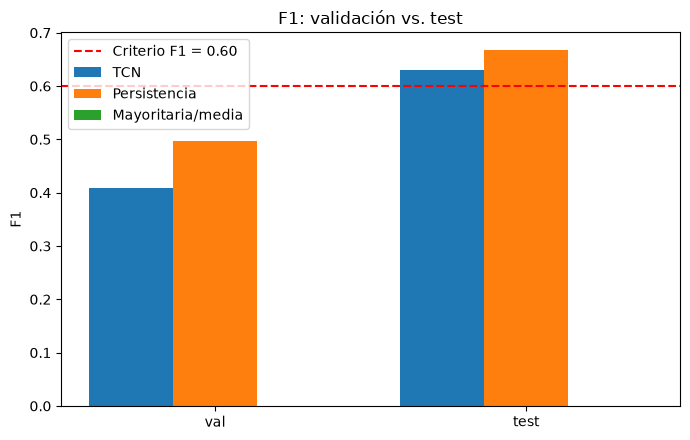

F1  TCN test: 0.6300 | persistencia: 0.6674 | base: 0.0000


In [10]:
key = "F1" if TASK == "classification" else "MAE"
labels = ["val", "test"]; x = np.arange(len(labels)); w = 0.27

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - w, res_model.loc[labels, key],   w, label="TCN")
ax.bar(x,     res_persist.loc[labels, key], w, label="Persistencia")
ax.bar(x + w, res_base.loc[labels, key],    w, label="Mayoritaria/media")
if TASK == "classification":
    ax.axhline(0.60, color="red", ls="--", label="Criterio F1 = 0.60")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel(key)
ax.set_title(f"{key}: validación vs. test"); ax.legend(); plt.tight_layout(); plt.show()

print(f"{key}  TCN test: {res_model.loc['test', key]:.4f} | "
      f"persistencia: {res_persist.loc['test', key]:.4f} | "
      f"base: {res_base.loc['test', key]:.4f}")


## 9. Curvas de entrenamiento

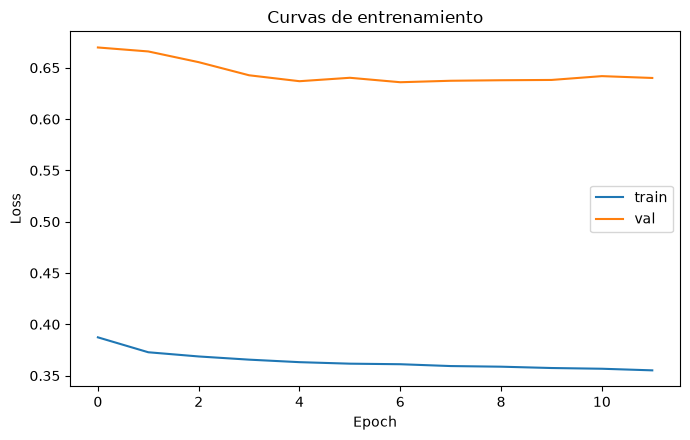

In [11]:
h = hist.history
plt.figure(figsize=(7, 4.5))
plt.plot(h["loss"], label="train"); plt.plot(h["val_loss"], label="val")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Curvas de entrenamiento")
plt.tight_layout(); plt.show()


## 10. Detalle en test (curvas, matriz de confusión / ROC o residuales)


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.617739
Precision 0.710974
   Recall 0.565534
 F1-Score 0.629969
  ROC-AUC 0.695218


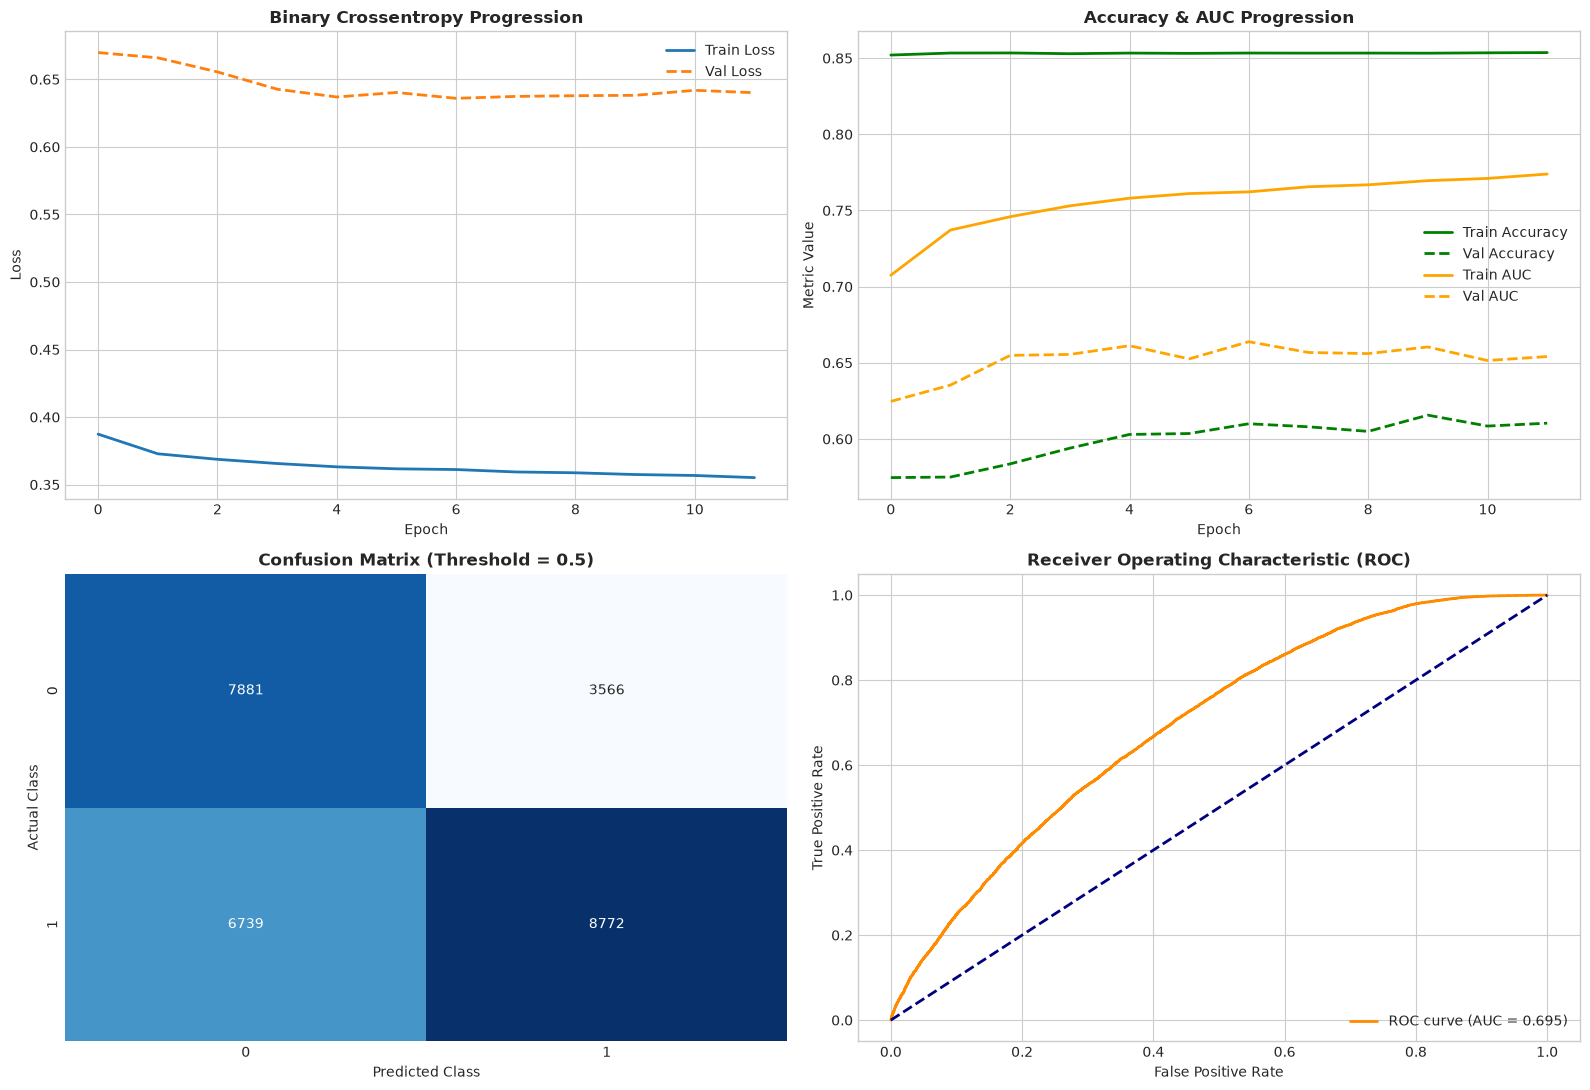

In [12]:
df_pred, df_metrics = tcn.evaluate(last["model"], last["history"], last["X_te"], last["y_te"])

## 11. Predicción vs. real en una semana (un robot)

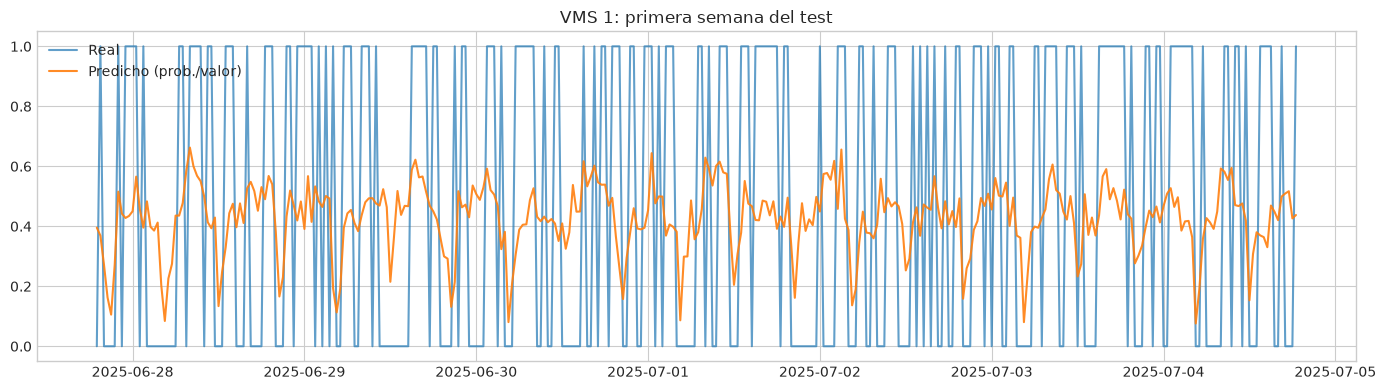

In [13]:
m = meta.iloc[last["te"]].copy()
m["real"] = last["y_te"]; m["pred"] = last["y_hat"]
robot = m["ms"].iloc[0]
s = m[m["ms"] == robot].head(336)          # 336 bloques = 7 días

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(s["bloque_tiempo"], s["real"], label="Real", alpha=0.7)
ax.plot(s["bloque_tiempo"], s["pred"], label="Predicho (prob./valor)", alpha=0.9)
ax.set_title(f"{robot}: primera semana del test"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Importancia de variables (por permutación, test)

Desordena una variable a la vez y mide cuánto empeora la métrica. Más caída = más importante. Se muestrea para que corra rápido.

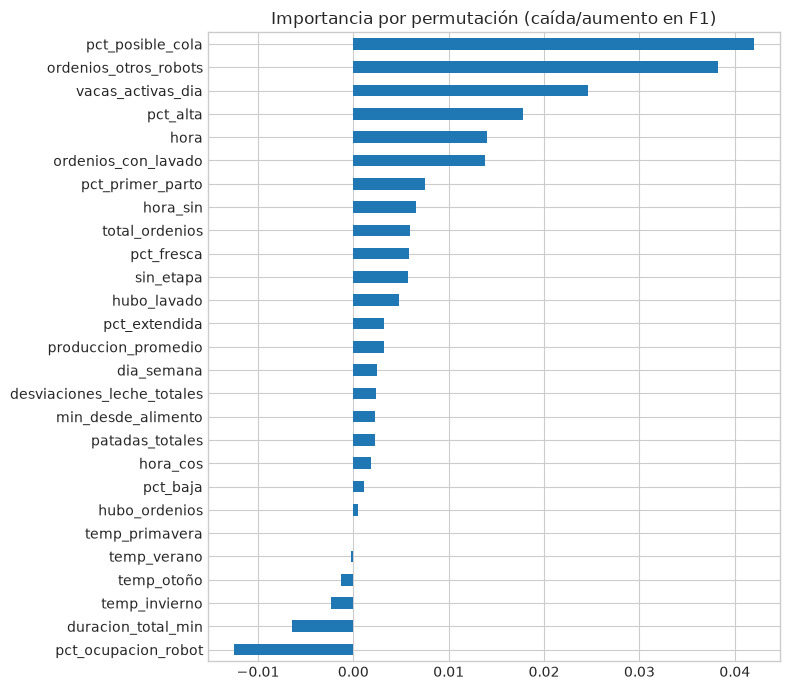

In [14]:
rng = np.random.default_rng(SEED)
Xp, yp = last["X_te"], last["y_te"]
idx = rng.choice(len(Xp), size=min(5000, len(Xp)), replace=False)
Xs, ys = Xp[idx], yp[idx]
mkey = "F1" if TASK == "classification" else "MAE"

base_val = metrics(ys, last["model"].predict(Xs, batch_size=512, verbose=0).ravel())[mkey]
imp = {}
for j, name in enumerate(tcn.feature_names_):
    Xperm = Xs.copy()
    Xperm[:, :, j] = Xperm[rng.permutation(len(Xs)), :, j]    # permuta la variable entre muestras
    v = metrics(ys, last["model"].predict(Xperm, batch_size=512, verbose=0).ravel())[mkey]
    imp[name] = (base_val - v) if TASK == "classification" else (v - base_val)

imp = pd.Series(imp).sort_values()
imp.plot.barh(figsize=(8, 7)); plt.title(f"Importancia por permutación (caída/aumento en {mkey})")
plt.tight_layout(); plt.show()

## 13. Guardar resultados

In [15]:
# @title
out = res_model.copy(); out.insert(0, "config", f"{TASK}|{VERSION}|w{WINDOW}|lv{LEVELS}")
out.to_csv(f"resultados_tcn_{TASK}_{VERSION}_w{WINDOW}.csv")
print("Guardado en el directorio actual de Colab.")

Guardado en el directorio actual de Colab.


## 14. Exportar Modelo

In [16]:
import json, joblib
from pathlib import Path

MODELS_DIR = Path(MODELING_PARENT) / "models" / "tcn"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tag = f"tcn_{TASK}_{VERSION}_w{WINDOW}" + ("_quick" if QUICK else "")
model_file  = MODELS_DIR / f"{tag}.keras"
scaler_file = MODELS_DIR / f"{tag}_scaler.joblib"
config_file = MODELS_DIR / f"{tag}_config.json"

last["model"].save(model_file)
joblib.dump(tcn.scaler, scaler_file)
json.dump({
    "task": TASK, "window": WINDOW, "version": VERSION, "levels": LEVELS,
    "threshold": tcn.threshold, "target": TARGET,
    "feature_names": tcn.feature_names_,
    "input_shape": list(last["X_te"].shape[1:]),
    "shift_target": True,
    "metrics_val": res_model.loc["val"].to_dict(),
    "metrics_test": res_model.loc["test"].to_dict(),
    "split": {"train": TRAIN_FRAC, "val": VAL_FRAC, "test": round(1 - TRAIN_FRAC - VAL_FRAC, 2)},
}, open(config_file, "w"), indent=2, ensure_ascii=False)

print("Guardado:")
for p in (model_file, scaler_file, config_file):
    print(" ", p)

Guardado:
  models/tcn/tcn_classification_base_w48.keras
  models/tcn/tcn_classification_base_w48_scaler.joblib
  models/tcn/tcn_classification_base_w48_config.json


## 15. Verificar exportación

In [17]:
loaded = tf.keras.models.load_model(model_file)
p_orig   = last["model"].predict(last["X_te"][:1000], verbose=0).ravel()
p_loaded = loaded.predict(last["X_te"][:1000], verbose=0).ravel()
print("Máx. diferencia:", float(np.abs(p_orig - p_loaded).max()))   # debe ser ~0

Máx. diferencia: 0.0


In [18]:
# df = pd.read_parquet(DATA_PATH) #RUTA ARCHIVO DATOS
# X_seq, y_seq, meta = tcn.prepare(df, df[TARGET]) # TARGET pct_posible_cola
# X_tr, X_te = tcn.scale(X_seq[tr], X_seq[te])

# loaded = tf.keras.models.load_model(model_file)
# p_loaded = loaded.predict(last["X_te"][:1000], verbose=0).ravel()